# Care Load Intelligence — Notebook 01: Data Quality & EDA
### Deep Dive into HHS UAC Operational Data, Reporting Irregularities, and Exploratory Patterns
**Author:** Utkarsh Sengar | **Live App:** https://cli-utkaresh-sengar-updated.streamlit.app/

---
## Overview
This notebook focuses on the foundation of the Care Load Intelligence platform: data engineering and quality validation. We inspect raw operational records, audit reporting intervals, and explore temporal patterns without corrupting the time series with naive zero-imputations.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

current_dir = Path(".").resolve()
REPO_ROOT = current_dir if (current_dir / "data").exists() else current_dir.parent

proc_path = REPO_ROOT / "data" / "processed" / "uac_observed_forecasting_data.csv"
raw_path = REPO_ROOT / "data" / "raw" / "HHS_Unaccompanied_Alien_Children_Program.csv"

df = pd.read_csv(proc_path)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)
target = "Children in HHS Care"

print(f"Loaded {len(df)} observed records from {proc_path.name}")
display(df.head(5))

Loaded 720 observed records from uac_observed_forecasting_data.csv


,Date,Children apprehended and placed in CBP custody*,Children in CBP custody,Children transferred out of CBP custody,Children in HHS Care,Children discharged from HHS Care
0,2023-01-12,33.0,53.0,34.0,6566,436.0
1,2023-01-22,32.0,49.0,39.0,7122,227.0
2,2023-01-23,32.0,50.0,39.0,7280,181.0
3,2023-01-24,47.0,42.0,47.0,7433,175.0
4,2023-01-25,20.0,22.0,41.0,7538,180.0


## 1. Calendar Span & Gap Analysis
We calculate the difference between calendar days and observed reporting dates.

In [2]:
min_d, max_d = df['Date'].min(), df['Date'].max()
cal_span = (max_d - min_d).days + 1
missing_d = cal_span - len(df)
df['Gap'] = df['Date'].diff().dt.days

print(f"Date Span:           {min_d:%Y-%m-%d} to {max_d:%Y-%m-%d}")
print(f"Calendar Days:       {cal_span}")
print(f"Observed Records:    {len(df)}")
print(f"Missing Calendar:    {missing_d} ({missing_d / cal_span * 100:.1f}%)")
print("\nDate Gap Counts:")
display(df['Gap'].value_counts().sort_index().to_frame('Occurrences'))

Date Span:           2023-01-12 to 2025-12-21
Calendar Days:       1075
Observed Records:    720
Missing Calendar:    355 (33.0%)

Date Gap Counts:


,Occurrences
Gap,
1.0,558
2.0,10
3.0,122
4.0,23
5.0,3
6.0,1
7.0,1
10.0,1


## 2. Visualizing Historical Care Load & Moving Averages

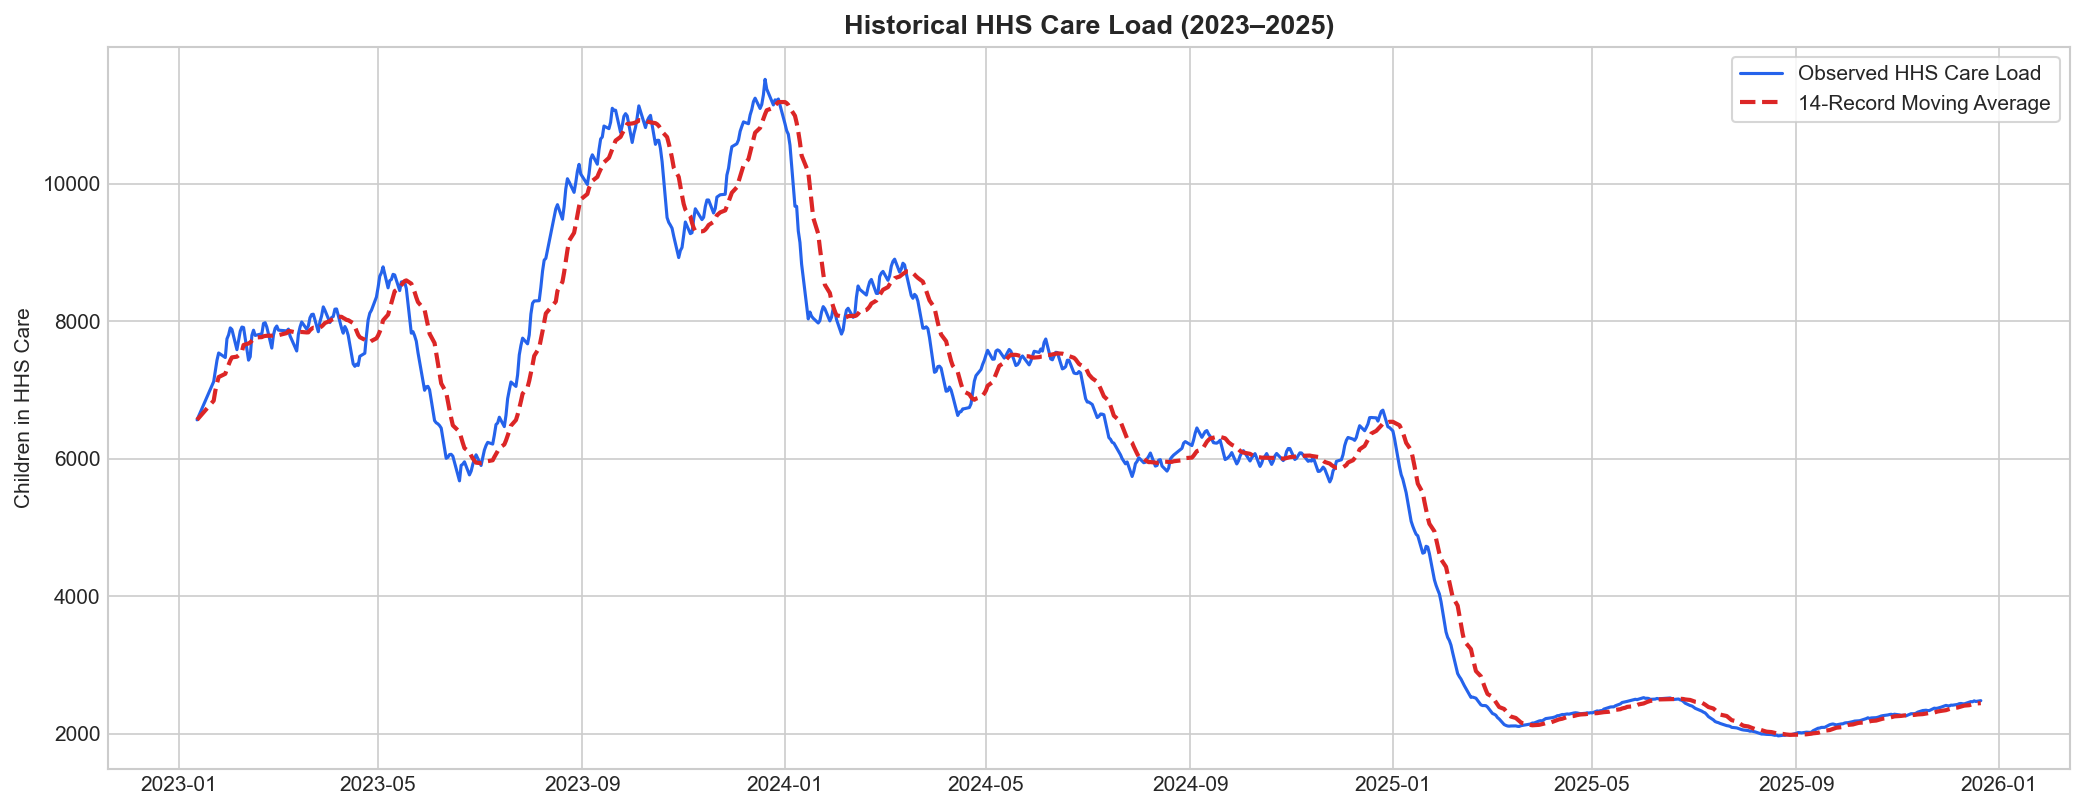

In [3]:
fig, ax = plt.subplots(figsize=(14, 5.5), dpi=150)
ax.plot(df['Date'], df[target], color='#2563eb', label='Observed HHS Care Load')
ax.plot(df['Date'], df[target].rolling(14, min_periods=1).mean(), color='#dc2626', linestyle='--', linewidth=2, label='14-Record Moving Average')
ax.set_title("Historical HHS Care Load (2023–2025)", fontsize=13, fontweight='bold')
ax.set_ylabel("Children in HHS Care")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

## 3. Operational Correlation Matrix

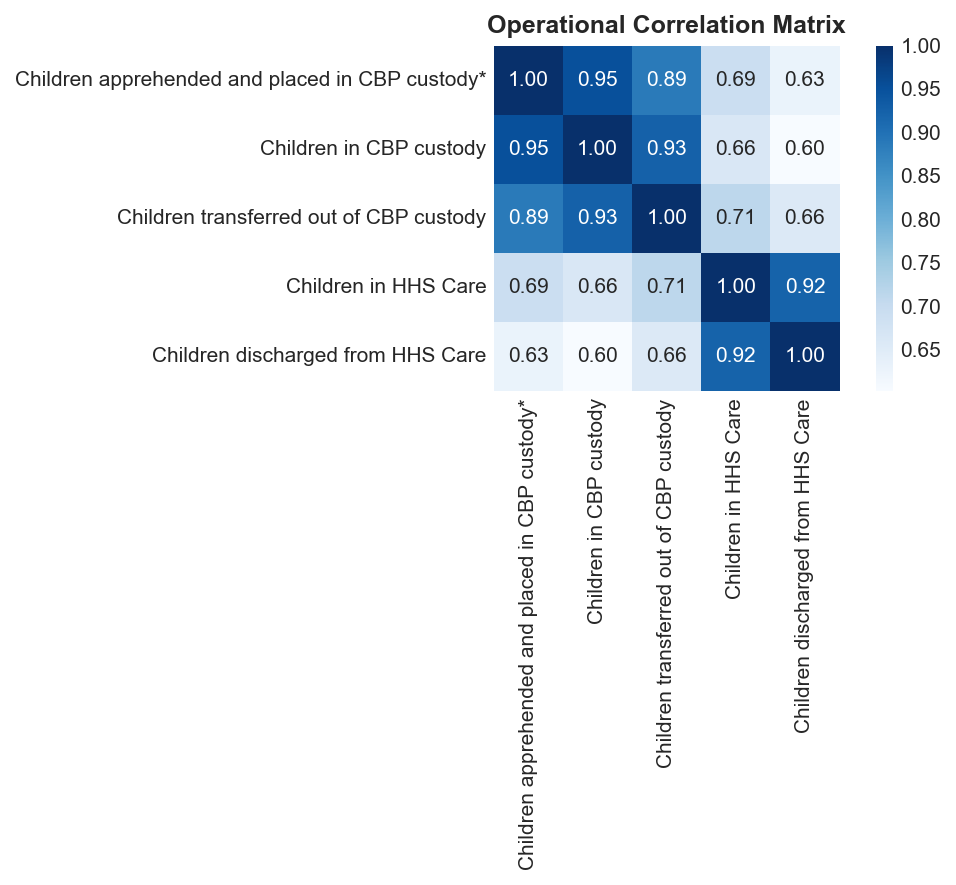

In [4]:
op_cols = [c for c in df.columns if c not in ['Date', 'Gap']]
fig, ax = plt.subplots(figsize=(8, 6), dpi=150)
sns.heatmap(df[op_cols].corr(), annot=True, fmt='.2f', cmap='Blues', square=True, ax=ax)
ax.set_title("Operational Correlation Matrix", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()